# HT-like stand density estimation with `lmfor::HTest` (Kansanen et al., CJFR 2021)

**Paper:** Kansanen, K., Packalen, P., et al. (2022) *Refining and evaluating a Horvitz–Thompson-like stand density estimator in individual tree detection based on airborne laser scanning.* Canadian Journal of Forest Research 52(4):527–538. [DOI 10.1139/cjfr-2021-0123](https://doi.org/10.1139/cjfr-2021-0123)

**Authors' implementation:** [`lmfor`](https://CRAN.R-project.org/package=lmfor) (GPL-2; L. Mehtätalo & K. Kansanen), function `HTest`, run here from the pinned CRAN mirror commit `6d1fb6adb6d0` (`R/HTest.R`).

**Purpose.** `HTest` computes a Horvitz–Thompson-like stand density estimate from individually detected tree crowns: each detected tree's detection probability is derived from the planar set formed by the larger crowns, and the function returns the density-corrected tree count `N` plus per-tree detectabilities. The tuning parameter `alpha` (−1…1) controls how easily a smaller tree is assumed detectable under larger crowns.

**Exact scope (partial demonstration).** Run the authors' own documented synthetic example (`man/HTest.Rd`: six detected trees with x, y, crown radius in metres; a 10 × 10 m estimation window; five centers inside, one outside to exercise edge effects) for `alpha = 1, 0, −0.75`, and visualize the input geometry and detectabilities.

**Out of scope.** The paper's two Finnish ALS/field datasets, functional k-NN estimation of the tuning parameter, and the benchmark RMSE comparison are **not** reproducible from public materials (datasets/code not located; article body paywalled). This notebook therefore does **not** verify the paper's published accuracy results.

**Execution model.** All scientific computation is the authors' R code, executed by `Rscript` inside this Colab VM; the surrounding Python is only a launcher (the Colab CLI runs a Python kernel). The pinned `R/HTest.R` is downloaded bit-exactly and verified by its Git blob SHA-1 before use.

**実行モデル（日本語）:** 科学計算はすべて著者本人の R コード（ピン留めしたコミットの `R/HTest.R`）を Colab VM 内の `Rscript` で実行します。Python のセルは起動・表示のためのラッパーにすぎません。入力は著者ドキュメント記載の合成例をそのまま使います。

**Execution status:** validated by a complete fresh Run all on a Colab **CPU** runtime (validation record at the end). No GPU is used or needed. / **実行状況:** CPU ランタイムで Run all により検証済み（末尾の検証記録を参照）。GPU は不要です。

## 1. Runtime selection

Select **Runtime → Change runtime type → CPU** (standard). The method is small-scale planar geometry (union/erosion/dilation of six discs); the pinned source contains no GPU code and no trained model, so a T4 would add nothing. **Run all** takes roughly 5–10 minutes if the `spatstat.geom` binaries install quickly (longer on a source-compile fallback); downloads are a few R packages (well under 100 MB).

**ランタイム（日本語）:** 「ランタイム → ランタイムのタイプを変更 → CPU」を選択してください。本手法は小規模な平面幾何計算で、GPU コードも学習済みモデルも不要です。Run all は概ね 5〜10 分程度です（ソースビルドにフォールバックした場合はさらにかかります）。

The next cell checks the interpreter and R availability, installing `r-base` via apt only if `Rscript` is missing (R is normally preinstalled on Colab CPU images).

In [ ]:
import shutil, subprocess, sys, platform

print("Python:", sys.version.split()[0], "|", platform.machine())
rscript = shutil.which("Rscript")
print("Rscript found at:", rscript)
if rscript is None:
    # Fallback only: Colab CPU images normally ship R already.
    print("R not found; installing r-base via apt (streamed, several minutes)...")
    subprocess.run(["apt-get", "update", "-qq"], check=True, timeout=600)
    subprocess.run(["apt-get", "install", "-y", "-qq", "r-base"], check=True, timeout=1800)
    rscript = shutil.which("Rscript")
assert rscript, "Rscript is unavailable even after the apt fallback"

rv = subprocess.run([rscript, "--vanilla", "-e", "cat(R.version.string)"],
                    text=True, timeout=300)
assert rv.returncode == 0, "R version probe failed"
print("R OK")

Python: 3.13.16 | x86_64
Rscript found at: /usr/bin/Rscript


R OK


## 2. Install the dependency used by the pinned code

`R/HTest.R` calls only `spatstat` **geometry** functions (`disc`, `union.owin`, `intersect.owin`, `erosion.owin`, `dilation.owin`, `inside.owin`, `area.owin`, `is.owin`, `square`), all provided by `spatstat.geom`. We install just that package instead of the full `lmfor` + whole `spatstat` umbrella (documented minimal adaptation: the pinned file is sourced verbatim, so the rest of `lmfor` is not needed).

Install order: (1) Posit Package Manager Ubuntu **binary** packages from a dated snapshot (fast, reproducible), (2) fallback to a source build from CRAN. The Ubuntu codename is read from `/etc/os-release`. Install output is streamed, not hidden. / **日本語:** ピン留めした著者コードに必要なのは `spatstat.geom` のみです。まず Posit P3M の Linux バイナリ（日付付きスナップショットで再現可能）を試し、失敗したら CRAN ソースビルドにフォールバックします。

In [ ]:
import pathlib, subprocess

codename = ""
for line in pathlib.Path("/etc/os-release").read_text().splitlines():
    if line.startswith("VERSION_CODENAME="):
        codename = line.split("=", 1)[1].strip()
print("Ubuntu codename:", codename)

lines = ['options(warn = 1)']
if codename in ("focal", "jammy", "noble"):
    repos = "https://packagemanager.posit.co/cran/__linux__/" + codename + "/2026-10-01"
    print("P3M binary repo:", repos)
    lines += [
        'if (!requireNamespace("spatstat.geom", quietly = TRUE)) {',
        '  install.packages("spatstat.geom", repos = c(P3M = "' + repos + '"))',
        '}',
    ]
lines += [
    'if (!requireNamespace("spatstat.geom", quietly = TRUE)) {',
    '  cat("Binary route unavailable or failed; falling back to CRAN source build...\\n")',
    '  install.packages("spatstat.geom", repos = "https://cloud.r-project.org")',
    '}',
    'stopifnot(requireNamespace("spatstat.geom", quietly = TRUE))',
    'cat("spatstat.geom version:", as.character(packageVersion("spatstat.geom")), "\\n")',
    'cat("R:", R.version.string, "\\n")',
]
pathlib.Path("/content/install_spatstat.R").write_text("\n".join(lines) + "\n")

res = subprocess.run(["Rscript", "--vanilla", "/content/install_spatstat.R"],
                     capture_output=True, text=True, timeout=3600)
if res.returncode != 0:
    print("INSTALL FAILED - stdout tail:\n", res.stdout[-4000:])
    print("stderr tail:\n", res.stderr[-2000:])
assert res.returncode == 0, "spatstat.geom installation failed (see captured output above)"
print(res.stdout[-1500:])
print("spatstat.geom ready")

Ubuntu codename: noble
P3M binary repo: https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01


include" -DNDEBUG       -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3  -c veegraf.c -o veegraf.o
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG       -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3  -c xyseg.c -o xyseg.o
x86_64-linux-gnu-gcc -std=gnu2x -shared -L/usr/lib/R/lib -Wl,-Bsymbolic-functions -flto=auto -ffat-lto-objects -Wl,-z,relro -o spatstat.geom.so areadiff.o auctionbf.o bdrymask.o clos

## 3. Fetch the pinned author code and verify it

Download `R/HTest.R` exactly at the pinned mirror commit and verify its **Git blob SHA-1** (the object hash recorded in the commit tree) and SHA-256 before running anything. If the hash does not match, the notebook stops rather than executing unverified code. / **日本語:** ピン留めしたコミットから `R/HTest.R` を取得し、Git blob SHA-1 と SHA-256 を検証してから使います。一致しない場合は実行せず停止します。

In [ ]:
import hashlib, pathlib, urllib.request

COMMIT = "6d1fb6adb6d045047529ade09de395aeb4e4d7a0"
EXPECTED_GIT_SHA1 = "1617a5546a41ddcfae4790800fc4a915aefc990a"
url = "https://raw.githubusercontent.com/cran/lmfor/" + COMMIT + "/R/HTest.R"
data = urllib.request.urlopen(url, timeout=60).read()

git_sha1 = hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()
print("source URL :", url)
print("bytes      :", len(data))
print("sha256     :", hashlib.sha256(data).hexdigest())
print("git blob   :", git_sha1)
assert git_sha1 == EXPECTED_GIT_SHA1, "Pinned source hash mismatch - refusing to execute"

pathlib.Path("/content/HTest.R").write_bytes(data)
print("Pinned author code verified and saved to /content/HTest.R")

source URL : https://raw.githubusercontent.com/cran/lmfor/6d1fb6adb6d045047529ade09de395aeb4e4d7a0/R/HTest.R
bytes      : 4430
sha256     : 12e450e606224dcca42956576a3a049101d088a91aa21339b310d83d0e07c959
git blob   : 1617a5546a41ddcfae4790800fc4a915aefc990a
Pinned author code verified and saved to /content/HTest.R


## 4. Input preview: the documented synthetic treelist

The minimal input is the authors' own example treelist from `man/HTest.Rd` — no external dataset is needed: six detected trees with (x, y, crown radius) in metres. Five crown centers lie inside the 10 × 10 m window; one (T6, at (11, 11)) lies outside, but its 3 m crown intersects the window, illustrating the documented edge-effect handling (the estimate uses only trees whose centers are inside the window, while larger outside crowns still influence detectabilities). The plot below shows the window, the crown discs, and the detected centers — an input view rendered from the actual data, not a paper figure. / **日本語:** 入力は著者ドキュメント記載の合成データ（6 本の検出木: 中心座標と樹冠半径、単位 m）のみです。T6 の中心はウィンドウ外ですが樹冠が接しています。下図は実データから描いた入力プレビューであり、論文の図ではありません。

Treelist (x_m, y_m, crown_radius_m) in metres:
       x_m   y_m crown_radius_m
[1,]  6.75  1.36           1.29
[2,]  8.65  3.10           2.31
[3,]  3.95  6.66           1.80
[4,]  2.00  2.00           2.00
[5,]  2.00  4.00           1.50
[6,] 11.00 11.00           3.00
null device 
          1 
preview written



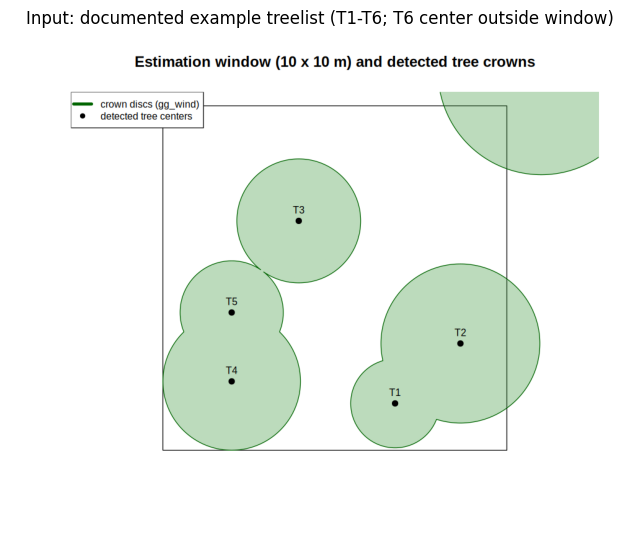

In [ ]:
import pathlib, subprocess

preview_r = r'''
suppressPackageStartupMessages(library(spatstat.geom))
source("/content/HTest.R")   # authors' pinned code, verified above
w <- square(10)              # 10 x 10 m estimation window (man/HTest.Rd example)
x <- cbind(c(6.75, 8.65, 3.95, 2, 2, 11),
           c(1.36, 3.10, 6.66, 2, 4, 11),
           c(1.29, 2.31, 1.80, 2, 1.5, 3))
colnames(x) <- c("x_m", "y_m", "crown_radius_m")
cat("Treelist (x_m, y_m, crown_radius_m) in metres:\n"); print(x)
ok <- tryCatch({png("/content/inputs_preview.png", width = 1000, height = 820,
                    res = 120, type = "cairo"); TRUE}, error = function(e) FALSE)
if (!isTRUE(ok)) png("/content/inputs_preview.png", width = 1000, height = 820, res = 120)
plot(w, main = "Estimation window (10 x 10 m) and detected tree crowns")
plot(gg_wind(x), add = TRUE, col = rgb(0.25, 0.6, 0.25, 0.35), border = "darkgreen")
points(x[, 1], x[, 2], pch = 19)
text(x[, 1], x[, 2], labels = sprintf("T%d", 1:6), pos = 3, cex = 0.8)
legend("topleft", legend = c("crown discs (gg_wind)", "detected tree centers"),
       col = c("darkgreen", "black"), pch = c(NA, 19), lwd = c(4, NA), cex = 0.8)
dev.off()
cat("preview written\n")
'''
pathlib.Path("/content/preview.R").write_text(preview_r)
res = subprocess.run(["Rscript", "--vanilla", "/content/preview.R"],
                     capture_output=True, text=True, timeout=600)
if res.returncode != 0:
    print("PREVIEW FAILED - stderr tail:\n", res.stderr[-2000:])
assert res.returncode == 0, "input preview failed"
print(res.stdout)

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
img = mpimg.imread("/content/inputs_preview.png")
plt.figure(figsize=(8, 6.6))
plt.imshow(img)
plt.axis("off")
plt.title("Input: documented example treelist (T1-T6; T6 center outside window)")
plt.show()

## 5. Core method: `HTest` on the minimal example

Run the authors' `HTest` on the verified input for the three documented tuning-parameter values. Interpretation of `alpha` from the authors' documentation: `alpha = 1` — a tree is detected unless fully covered by larger crowns; `alpha = 0` — detected if its center point is not covered; `alpha = -0.75` — an intermediate, stricter case toward `alpha = -1` (fully outside larger crowns). Output: `N` (HT-like estimated tree count in the window) and per-tree detectabilities, written to CSV. Plausibility expectation: `N ≥ 5` (the five in-window trees), with smaller, crowded trees corrected upward most — detectability also depends on the neighbouring larger crowns, not only on a tree's own radius. / **日本語:** 著者の `HTest` をドキュメント記載の 3 つの alpha 値で実行します。出力は推定本数 `N` と各木の検出確率（detectability）で、CSV にも保存されます。

In [ ]:
import pathlib, subprocess

htest_r = r'''
suppressPackageStartupMessages(library(spatstat.geom))
source("/content/HTest.R")
w <- square(10)
x <- cbind(c(6.75, 8.65, 3.95, 2, 2, 11),
           c(1.36, 3.10, 6.66, 2, 4, 11),
           c(1.29, 2.31, 1.80, 2, 1.5, 3))
alphas <- c(1, 0, -0.75)
det_rows <- list(); k <- 0; n_rows <- list(); m <- 0
for (a in alphas) {
  res <- HTest(x, w, a)
  n_ha <- res$N * 100   # 10 x 10 m = 100 m2; 1 ha = 100 such windows
  cat(sprintf("alpha = %.2f -> N = %.6f trees in 100 m2 (%.4f trees/m2, %.1f trees/ha)\n",
              a, res$N, res$N / 100, n_ha))
  cat("Per-tree detectabilities (sorted by crown radius r, m):\n"); print(res$treelist)
  m <- m + 1
  n_rows[[m]] <- data.frame(alpha = a, N_estimate = res$N, density_trees_per_ha = n_ha)
  for (i in seq_len(nrow(res$treelist))) {
    k <- k + 1
    det_rows[[k]] <- data.frame(alpha = a, rank_by_radius = i,
                                r_m = res$treelist[i, "r"],
                                detectability = res$treelist[i, "detectability"])
  }
}
write.csv(do.call(rbind, det_rows), "/content/htest_detectabilities.csv", row.names = FALSE)
write.csv(do.call(rbind, n_rows), "/content/htest_N_summary.csv", row.names = FALSE)
cat("CSV outputs written.\n")
'''
pathlib.Path("/content/run_htest.R").write_text(htest_r)
res = subprocess.run(["Rscript", "--vanilla", "/content/run_htest.R"],
                     capture_output=True, text=True, timeout=600)
if res.returncode != 0:
    print("HTEST FAILED - stderr tail:\n", res.stderr[-2000:])
assert res.returncode == 0, "HTest execution failed"
print(res.stdout)

alpha = 1.00 -> N = 5.112015 trees in 100 m2 (0.0511 trees/m2, 511.2 trees/ha)
Per-tree detectabilities (sorted by crown radius r, m):
        r detectability
[1,] 2.31     1.0000000
[2,] 2.00     0.9969811
[3,] 1.80     0.9905725
[4,] 1.50     0.9686353
[5,] 1.29     0.9371288
alpha = 0.00 -> N = 7.011580 trees in 100 m2 (0.0701 trees/m2, 701.2 trees/ha)
Per-tree detectabilities (sorted by crown radius r, m):
        r detectability
[1,] 2.31     1.0000000
[2,] 2.00     0.8357545
[3,] 1.80     0.7100917
[4,] 1.50     0.6083047
[5,] 1.29     0.5672553
alpha = -0.75 -> N = 14.690655 trees in 100 m2 (0.1469 trees/m2, 1469.1 trees/ha)
Per-tree detectabilities (sorted by crown radius r, m):
        r detectability
[1,] 2.31     1.0000000
[2,] 2.00     0.6111168
[3,] 1.80     0.3842437
[4,] 1.50     0.1976599
[5,] 1.29     0.2276557
CSV outputs written.



## 6. Result graph: detectability vs crown radius

A graph created for this notebook from the actual `HTest` outputs (not an author figure): per-tree detectability against crown radius for each `alpha`. Smaller crowns under larger neighbours get the lowest detectabilities; how strongly `alpha` penalizes crowding increases from `alpha = 1` (most permissive) toward `alpha = -0.75` / `-1` (strictest). / **日本語:** 実行結果から検出確率と樹冠半径の関係を描いた、このノートブック用の追加グラフです（著者の図ではありません）。小さい樹冠ほど、また alpha が -1 側ほど検出確率が下がります。

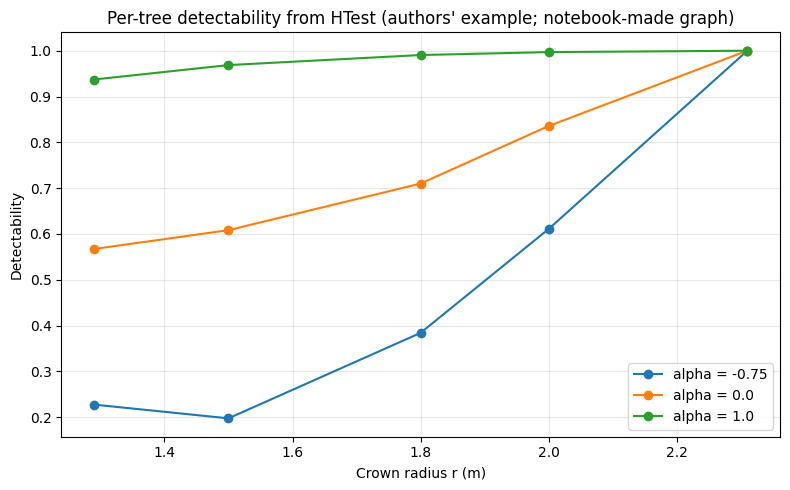

               detectability                       r_m            
alpha                  -0.75      0.00      1.00 -0.75  0.00  1.00
rank_by_radius                                                    
1                   1.000000  1.000000  1.000000  2.31  2.31  2.31
2                   0.611117  0.835755  0.996981  2.00  2.00  2.00
3                   0.384244  0.710092  0.990573  1.80  1.80  1.80
4                   0.197660  0.608305  0.968635  1.50  1.50  1.50
5                   0.227656  0.567255  0.937129  1.29  1.29  1.29


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

det = pd.read_csv("/content/htest_detectabilities.csv")
fig, ax = plt.subplots(figsize=(8, 5))
for a, grp in det.groupby("alpha"):
    ax.plot(grp["r_m"], grp["detectability"], marker="o", label=f"alpha = {a}")
ax.set_xlabel("Crown radius r (m)")
ax.set_ylabel("Detectability")
ax.set_title("Per-tree detectability from HTest (authors' example; notebook-made graph)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(det.pivot_table(index="rank_by_radius", columns="alpha",
                      values=["r_m", "detectability"]).to_string())

## 7. Results table and CSV export

Summary of the HT-like estimates `N` for the three `alpha` values, plus the saved CSV (written inside the Colab VM under `/content/`, downloadable from the file browser). These are the executed results of the authors' estimator on the documented example; they are not comparable to any published accuracy figure. / **日本語:** 3 つの alpha について推定本数 `N` の要約表です。CSV は Colab VM 内の `/content/` に保存されます。

In [ ]:
import pandas as pd

summary = pd.read_csv("/content/htest_N_summary.csv")
print(summary.to_string(index=False))
print("\nFiles saved under /content/: HTest.R (pinned author code), inputs_preview.png,")
print("htest_detectabilities.csv, htest_N_summary.csv")

 alpha  N_estimate  density_trees_per_ha
  1.00    5.112015            511.201459
  0.00    7.011580            701.158018
 -0.75   14.690655           1469.065466

Files saved under /content/: HTest.R (pinned author code), inputs_preview.png,
htest_detectabilities.csv, htest_N_summary.csv


## 8. Interpretation, validation record, and references

**What was executed.** The authors' pinned `HTest` implementation (CRAN mirror commit `6d1fb6adb6d0`, blob SHA-1 `1617a5546a41` verified in-notebook) ran on the documented synthetic treelist for `alpha = 1, 0, −0.75`, producing the density estimates and detectabilities shown above. All computation ran on a fresh Colab **CPU** runtime; no GPU is involved anywhere in the method.

**Scientific reading.** The demonstration shows the paper's core estimator-computation step: detection probabilities derived from the planar set of larger crowns, and the HT-like correction `N = sum(1/detectability)`. The per-tree detectabilities and their `alpha`-dependence follow the authors' documented detection-condition semantics (fully-covered / center-point / fully-outside rules).

**Differences from the paper.** Not verified here, and not verifiable from public materials: the paper's own ALS/field data, the functional k-NN estimation of the tuning parameter, the two-dataset fit/predict evaluation, and the reported 13 % RMSE improvement over the benchmark. The article body is paywalled; this notebook deliberately demonstrates only what the authors' public code and documentation fully support. No numeric reference values for this example exist in the accessible materials, so results are checked for internal plausibility (`N ≥ 5` in-window trees; detectabilities in (0, 1]; smaller and more crowded trees generally less detectable), not against a published figure.

**Validation record.** This notebook was executed top-to-bottom in a fresh Colab CPU session via the project's Colab CLI; the archived executed notebook, session log, and validation date are recorded in the run report. / **検証記録（日本語）:** 本ノートブックは新しい Colab CPU セッションで Run all 検証されました。実行済みノートブックとセッションログの実体はプロジェクトの実行記録に保存されています。

**References.**
- Kansanen, K., Packalen, P., et al. (2022). Refining and evaluating a Horvitz–Thompson-like stand density estimator in individual tree detection based on airborne laser scanning. *Canadian Journal of Forest Research* 52(4):527–538. doi:10.1139/cjfr-2021-0123.
- Kansanen, K., Vauhkonen, J., Lähivaara, T., Mehtätalo, L. (2016). Stand density estimators based on individual tree detection and stochastic geometry. *CJFR* 46(11):1359–1366. doi:10.1139/cjfr-2016-0181.
- Mehtätalo, L., Kansanen, K. `lmfor`: Functions for Forest Biometrics, CRAN, version 1.7, GPL-2. `HTest` documentation (`man/HTest.Rd`) and source (`R/HTest.R`), mirror commit `6d1fb6adb6d045047529ade09de395aeb4e4d7a0`.
- Baddeley, A., Rubak, E., Turner, R. (2015). *Spatial Point Patterns* — the `spatstat` package used by the authors' code.

**PhenoPaper investigation** `p-187d7e1f38b2a4425eb3ebdba448a71f-20261007T110220Z-4031630` was used as prior research guidance; primary proof here comes from the pinned author code and documentation only.